# Week 9: Option Greeks & Risk Sensitivities

How can a call lose money when its stock goes up? We will derive the five main Greeks from last week's Black–Scholes formula, use delta to size a stock hedge, and check one price move in Python.

[Week 8 notebook](https://github.com/novaquantclub/quant-roadmap/blob/main/Week%208/Week_8_Options_Final_Executed.ipynb) · [Quant Roadmap](https://github.com/novaquantclub/quant-roadmap)

## 1. From the binomial hedge ratio to delta

Revisit a one-step tree. The stock is \$100 today and can finish at \$120 or \$80. A call with strike \$95 pays \$25 or \$0. Subtract the two replication equations. The bond pays the same in both states, so it drops out:

$$
\Delta_{\mathrm{tree}}=\frac{C_u-C_d}{S_u-S_d}=\frac{25-0}{120-80}=0.625.
$$

The replicating portfolio holds 0.625 shares per option share. In Black–Scholes, spot varies continuously, so the hedge ratio is the **local slope** $\Delta=\partial C/\partial S$. Gamma tells us how quickly that slope changes.

## 2. Derive delta and gamma

Start with a European call on a stock that pays no dividends. $S$ is spot, $K$ is the strike (called $X$ in Week 8), $T$ is time remaining in years, $r$ is the continuously compounded annual rate, and $\sigma$ is annual volatility. $N$ is the standard normal CDF and $\phi=N'$ is its density.

$$
C=S N(d_1)-Ke^{-rT}N(d_2),\qquad
d_1=\frac{\ln(S/K)+(r+\tfrac12\sigma^2)T}{\sigma\sqrt{T}},\qquad
d_2=d_1-\sigma\sqrt{T}.
$$

**Why the chain-rule terms cancel.** From the normal density,

$$
\frac{\phi(d_1)}{\phi(d_2)}
=e^{-(d_1^2-d_2^2)/2}
=e^{-d_1\sigma\sqrt T+\sigma^2T/2}
=e^{-\ln(S/K)-rT}.
$$

Therefore $S\phi(d_1)=Ke^{-rT}\phi(d_2)$. Holding $K,T,r,\sigma$ fixed, both $d_1$ and $d_2$ change by the same amount when we bump spot because $d_1-d_2=\sigma\sqrt T$ is constant in spot. Differentiate the call price:

$$
\begin{aligned}
\Delta=\frac{\partial C}{\partial S}
&=N(d_1)+S\phi(d_1)\frac{\partial d_1}{\partial S}
-Ke^{-rT}\phi(d_2)\frac{\partial d_2}{\partial S}\\
&=N(d_1).
\end{aligned}
$$

Now differentiate delta. The derivative of $\ln(S/K)$ with respect to spot is $1/S$, so

$$
\Gamma=\frac{\partial \Delta}{\partial S}
=\phi(d_1)\frac{\partial d_1}{\partial S}
=\frac{\phi(d_1)}{S\sigma\sqrt T}.
$$

**Read the numbers.** The Week 8 call has $\Delta\approx0.6665$ and $\Gamma\approx0.01455$. A long contract on 100 shares has the same initial spot exposure as about 66.65 shares. Shorting that many shares offsets the initial delta. After a \$1 spot-only rise, positive gamma says to short roughly 1.45 more shares to restore the hedge.



#The graphs below show how a call’s stock hedge changes as the stock price moves. 
Left graph — Delta tells you how many shares to hedge. A delta of 0.60 means a long call on 100 shares has roughly the same immediate stock exposure as 60 shares. To hedge it, you’d short 60 shares. With one week left, delta is close to 0 well below the strike and close to 1 well above it. Around the strike, a small stock move can change the hedge substantially.

Right graph — Gamma tells you how fast that hedge changes. At each stock price, gamma is the slope of the delta curve on the left. Near the strike, the orange delta curve is steep, so the orange gamma curve peaks. Gamma there is about 0.06 with one week left, versus about 0.017 with three months left. For a 100-share long call, a $1 stock rise near the strike means you’d short roughly 6 more shares with one week left, versus 1.7 more shares with three months left.

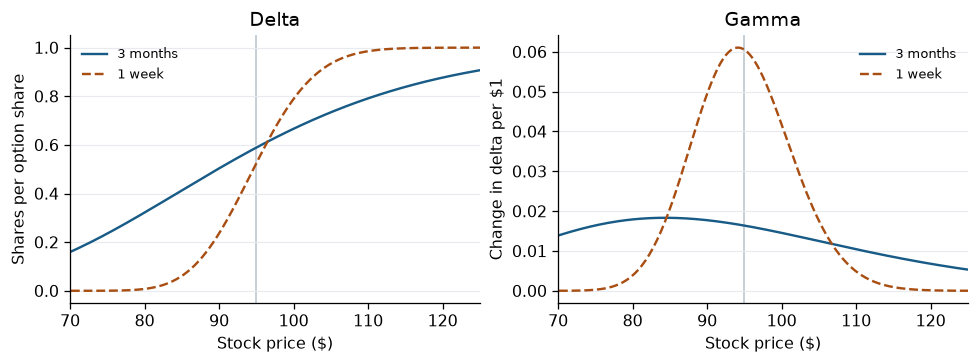

The vertical line marks the \$95 strike. With one week left, delta rises more sharply near the strike, so gamma is higher there. Where would the hedge go stale fastest?

## 3. Derive vega, theta and rho

Write $B=Ke^{-rT}$ for the discounted strike. The same identity combines the two chain-rule terms into a single term. With $K$ fixed,

$$
dC=N(d_1)\,dS-N(d_2)\,dB+S\phi(d_1)\,d(d_1-d_2).
$$

For each Greek below, move one input at a time and hold the rest fixed.

**Vega.** The discounted strike stays fixed. Since $d_1-d_2=\sigma\sqrt T$, its volatility derivative is $\sqrt T$.

$$
\frac{\partial C}{\partial \sigma}=S\phi(d_1)\sqrt T.
$$

Vega is positive for a long call. Divide this derivative by 100 to quote the change in premium for **one percentage point** of volatility, such as 50% to 51%.

**Theta.** Both terms move with time remaining: $\partial B/\partial T=-rB$ and $\partial(d_1-d_2)/\partial T=\sigma/(2\sqrt T)$. Calendar time passing makes $T$ fall, so reverse the sign of the derivative with respect to remaining time.

$$
\Theta_{\mathrm{year}}=-\frac{\partial C}{\partial T}
=-rKe^{-rT}N(d_2)-\frac{S\phi(d_1)\sigma}{2\sqrt T}.
$$

Divide by 365 for an estimate **per calendar day**. With the other inputs fixed, one day passing costs this call about \$0.064 per share.

**Rho.** The gap between $d_1$ and $d_2$ stays fixed. The rate changes the discounted strike through $\partial B/\partial r=-TB$.

$$
\rho_{\mathrm{decimal}}=\frac{\partial C}{\partial r}
=TKe^{-rT}N(d_2).
$$

A higher rate lowers the present value of the strike the call holder would pay. Divide by 100 for rho **per percentage point** of the annual rate.

**What about puts and dividends?** With no dividends, put–call parity is $P=C-S+B$. The put's delta is therefore $\Delta_{\mathrm{call}}-1$, its gamma and vega match the call's, and its rho is negative. Put theta can have either sign. Lab 9 adds a continuous dividend yield $q$ to the model. Holding the other inputs fixed, a higher yield lowers call value and raises put value.

### Put Greeks from put–call parity

For a European call and put on the same non-dividend-paying stock, with the same strike $K$ and expiry, put–call parity gives

$$
V_{\mathrm{put}} = V_{\mathrm{call}} - S + B,
\qquad B = Ke^{-rT},
$$

| Greek | Call formula | Put formula | What it measures |
| --- | --- | --- | --- |
| Delta | $\Delta_{\mathrm{call}} = N(d_1)$ | $\Delta_{\mathrm{put}} = N(d_1) - 1$ | How much the option price changes for a small move in the stock price. |
| Gamma | $\Gamma_{\mathrm{call}} = \dfrac{\phi(d_1)}{S\sigma\sqrt{T}}$ | $\Gamma_{\mathrm{put}} = \Gamma_{\mathrm{call}}$ | How much delta changes for a small move in the stock price. |
| Vega | $\nu_{\mathrm{call}} = S\phi(d_1)\sqrt{T}$ | $\nu_{\mathrm{put}} = \nu_{\mathrm{call}}$ | How much the option price changes when volatility moves. |
| Theta | $\Theta_{\mathrm{call}} = -\dfrac{S\phi(d_1)\sigma}{2\sqrt{T}} - rB\,N(d_2)$ | $\Theta_{\mathrm{put}} = \Theta_{\mathrm{call}} + rB$ | How much the option price changes as calendar time passes, holding the other inputs fixed. |
| Rho | $\rho_{\mathrm{call}} = TB\,N(d_2)$ | $\rho_{\mathrm{put}} = -TB\,N(-d_2)$ | How much the option price changes when the risk-free interest rate moves. |

Here $B = Ke^{-rT}$ is the present value of the strike, $T$ is the time remaining until expiry, $N$ is the standard normal CDF, and $\phi$ is its density.

## 4. Python · Check the slope at spot 100

Use the same inputs as Week 8. Run the setup cell, then keep every input except spot fixed. The slope between the prices at \$99.90 and \$100.10 approximates delta at \$100:

$$
\Delta_{\mathrm{FD}}\approx\frac{C(S+h)-C(S-h)}{2h},\qquad h=0.10.
$$

In [3]:
from math import erfc # Function to compute the size of the tail of a bell curve

import numpy as np


# In this first section we are essentually building the pricer 
base = dict(S=100.0, K=95.0, T=0.25, r=0.10, sigma=0.50, q=0.0) #Starting inputs of the option
DAYS_PER_YEAR = 365

normal_cdf = np.vectorize(lambda x: 0.5 * erfc(-x / np.sqrt(2)), otypes=[float])

 
def bs_terms(S, K, T, r, sigma, q): #Defines the terms used in the Black-Scholes formula
    root_T = np.sqrt(T)
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * root_T)
    d2 = d1 - sigma * root_T
    spot_discount = np.exp(-q * T)
    discounted_strike = K * np.exp(-r * T)
    return root_T, d1, d2, spot_discount, discounted_strike


def price(S, K, T, r, sigma, q=0.0, kind="call"):   # This is the function that will calculate the price of the option, automatically assuming it is a call option unless specified otherwise
    root_T, d1, d2, spot_discount, discounted_strike = bs_terms(S, K, T, r, sigma, q)
    if kind == "call":
        return S * spot_discount * normal_cdf(d1) - discounted_strike * normal_cdf(d2)
    if kind == "put":
        return discounted_strike * normal_cdf(-d2) - S * spot_discount * normal_cdf(-d1)
    raise ValueError("kind must be 'call' or 'put'")


initial_price = price(**base)
print(f"Week 8 call price: ${initial_price:.4f} per share")

Week 8 call price: $13.6953 per share


In [4]:
_, d1, _, _, _ = bs_terms(**base) #The underscore is used to ignore the other values returned by the function, since we only need d1 for delta calculation
delta = float(normal_cdf(d1))
h = 0.10
up = price(**(base | {"S": base["S"] + h})) #Makes a new dictionary with the same keys as base, but with the value of S increased by h
down = price(**(base | {"S": base["S"] - h})) #Makes a new dictionary with the same keys as base, but with the value of S decreased by h
delta_fd = (up - down) / (2 * h)
print(f"Analytical delta: {delta:.6f} | Bump-and-reprice delta: {delta_fd:.6f}") #Compares the analytical delta with the bump-and-reprice delta, which is calculated by bumping the underlying price up and down by a small amount and calculating the change in option price

Analytical delta: 0.666465 | Bump-and-reprice delta: 0.666465


## Lab 9 · Call Greeks and hedging

Both examples use the European call from Section 4. Run the two Python cells above before rerunning the lab.

### 1. Measure the Greeks and compare two hedges

**Start at spot \$100.** The first cell estimates all five call Greeks by changing one input at a time.

- `base | changes` creates a new set of inputs with your changes. `price(**...)` passes those inputs to the pricer by name.
- `spot_greeks` reprices at $S_d$, $S_u$, and the center spot at the same maturity. Delta is $(V_d-V_u)/(S_d-S_u)$. Gamma compares the slope on either side of the center and divides by the spot bump again.
- `one_point = 0.01` means one percentage point. The vega and rho prices are two points apart, so dividing the price difference by two gives the change per point.
- `one_day = 1 / DAYS_PER_YEAR` converts a calendar day to years. Theta puts the price with less time remaining first because it represents a later calendar date. Divide the price difference by two to report it per calendar day.

In [5]:
def reprice(**changes):
    return float(price(**(base | changes)))


def spot_greeks(S, T, bump=0.10):
    S_d, S_u = S - bump, S + bump
    V_d = reprice(S=S_d, T=T)
    V_u = reprice(S=S_u, T=T)
    center_price = reprice(S=S, T=T)
    delta_fd = (V_d - V_u) / (S_d - S_u)
    gamma_fd = (V_u - 2 * center_price + V_d) / bump**2
    return delta_fd, gamma_fd


one_point = 0.01
one_day = 1 / DAYS_PER_YEAR
call_delta, call_gamma = spot_greeks(base["S"], base["T"])
vol, time_left, rate = base["sigma"], base["T"], base["r"]

vega_fd = (reprice(sigma=vol + one_point) - reprice(sigma=vol - one_point)) / 2
theta_fd = (reprice(T=time_left - one_day) - reprice(T=time_left + one_day)) / 2
rho_fd = (reprice(r=rate + one_point) - reprice(r=rate - one_point)) / 2

print(f"Delta: {call_delta:.6f} | Gamma: {call_gamma:.6f}")
print(f"Vega per IV point: {vega_fd:+.6f}")
print(f"Theta per day: {theta_fd:+.6f}")
print(f"Rho per rate point: {rho_fd:+.6f}")

Delta: 0.666465 | Gamma: 0.014547
Vega per IV point: +0.181840
Theta per day: -0.064328
Rho per rate point: +0.132377


**Move to the strike.** Compare the same call with three months and one week left. For a long call on 100 shares, `contract_shares * strike_gamma * hedge_spot_move` estimates how many extra shares to short after spot rises from \$95 to \$96. We check that estimate by recalculating delta at \$96 and using $100(\Delta_{96}-\Delta_{95})$.

The hedge needs about **1.62 more shares** with three months left and **5.97 more shares** with one week left. Section 2 shows why. The one-week delta curve is steeper near the strike, so the hedge changes more for the same stock move.

In [6]:
contract_shares = 100
strike = base["K"]
hedge_spot_move = 1.0

for label, maturity in [("3 months", base["T"]), ("1 week", 7 * one_day)]:
    strike_delta, strike_gamma = spot_greeks(strike, maturity)
    new_delta, _ = spot_greeks(strike + hedge_spot_move, maturity)
    estimated_shares = contract_shares * strike_gamma * hedge_spot_move
    recalculated_shares = contract_shares * (new_delta - strike_delta)
    print(f"{label}: delta {strike_delta:.4f} at $95 and {new_delta:.4f} at $96")
    print(f"  Extra shares to short: {estimated_shares:.2f} estimated | {recalculated_shares:.2f} recalculated")

3 months: delta 0.5890 at $95 and 0.6052 at $96
  Extra shares to short: 1.64 estimated | 1.62 recalculated
1 week: delta 0.5248 at $95 and 0.5845 at $96
  Extra shares to short: 6.05 estimated | 5.97 recalculated


### 2. Explain the P&L of a delta-hedged call

Return to the original call at spot \$100 with three months left. One day passes and spot rises to \$101. Implied volatility stays at 50% in the first case and falls to 45% in the second.

- `linear_pnl` adds the delta, vega, and theta contributions. The rate is unchanged, so rho contributes zero. `delta_gamma_pnl` adds $\tfrac12\Gamma(\Delta S)^2$ to account for the call's curvature as spot moves.
- Full repricing applies the three changes together. `iv_move_points * one_point` converts the volatility move to a decimal. The `T` line subtracts elapsed time. Subtracting `initial_price` gives the call P&L.
- `-delta * spot_move` is the P&L of the original short stock hedge. It is the same in both cases because spot rises by the same amount. Adding it to the call P&L gives the hedged result.

Gamma improves both estimates in this example. With unchanged IV, the estimate including gamma is within **\$0.0002** per option share of full repricing at the displayed precision. With IV down five points, the estimate is still about **\$0.0173** away because the Greeks also change as the inputs move.

The hedge loses **\$0.0573** per option share with flat IV and **\$0.9490** with IV down. The larger loss comes from the call's volatility exposure. The stock hedge offsets initial delta, while the position still has exposure to volatility, time, and curvature.

In [7]:
spot_move = 1.0
elapsed_days = 1
stock_pnl = -delta * spot_move
delta_pnl = call_delta * spot_move
theta_pnl = theta_fd * elapsed_days
gamma_pnl = 0.5 * call_gamma * spot_move**2
print(f"Stock hedge P&L in both cases: {stock_pnl:+.4f} per option share")

for iv_move_points in (0, -5):
    vega_pnl = vega_fd * iv_move_points
    linear_pnl = delta_pnl + vega_pnl + theta_pnl
    delta_gamma_pnl = linear_pnl + gamma_pnl

    call_pnl = reprice(
        S=base["S"] + spot_move,
        sigma=base["sigma"] + iv_move_points * one_point,
        T=base["T"] - elapsed_days * one_day,
    ) - initial_price
    hedged_pnl = call_pnl + stock_pnl
    linear_error = abs(call_pnl - linear_pnl)
    delta_gamma_error = abs(call_pnl - delta_gamma_pnl)

    print(f"\nIV move: {iv_move_points:+d} points")
    print(f"  Delta {delta_pnl:+.4f} | Vega {vega_pnl:+.4f} | Theta {theta_pnl:+.4f} | Gamma {gamma_pnl:+.4f}")
    print(f"  Linear estimate: {linear_pnl:+.4f} | With gamma: {delta_gamma_pnl:+.4f}")
    print(f"  Absolute error: {linear_error:.4f} linear | {delta_gamma_error:.4f} with gamma")
    print(f"  Full call P&L: {call_pnl:+.4f} | Hedged P&L: {hedged_pnl:+.4f}")

Stock hedge P&L in both cases: -0.6665 per option share

IV move: +0 points
  Delta +0.6665 | Vega +0.0000 | Theta -0.0643 | Gamma +0.0073
  Linear estimate: +0.6021 | With gamma: +0.6094
  Absolute error: 0.0071 linear | 0.0002 with gamma
  Full call P&L: +0.6092 | Hedged P&L: -0.0573

IV move: -5 points
  Delta +0.6665 | Vega -0.9092 | Theta -0.0643 | Gamma +0.0073
  Linear estimate: -0.3071 | With gamma: -0.2998
  Absolute error: 0.0245 linear | 0.0173 with gamma
  Full call P&L: -0.2825 | Hedged P&L: -0.9490


### Reading

- [Options Industry Council · Understanding Options Greeks](https://prd-web.optionseducation.org/advancedconcepts/understanding-options-greeks)
- [CME Group · Options Premium and the Greeks](https://www.cmegroup.com/education/courses/option-greeks/options-the-greeks-options-premium-and-the-greeks)